# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 3</span>

In [9]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 03.1

## Result

In this exercise, we tackle the option pricing problem from two points of view: sampling the final price directly, or sampling the discretized $GBM(r,\sigma^2)$ path of the asset price.



**Direct sampling**

Under the risk-neutral measure, the price of the underlying asset at maturity $T$ follows a Geometric Brownian Motion with drift $r$ and volatility $\sigma$:

$$
S(T) = S_0 \exp\left[\left(r - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right], \qquad Z \sim \mathcal{N}(0,1).
$$

I sampled $S(T)$ directly in a single step, for $M = 10^4$ independent paths, divided into 100 blocks. For each path, I computed the discounted payoff of the European call and put options,

$$
C = e^{-rT}\max\big(S(T)-K,\,0\big), \qquad P = e^{-rT}\max\big(K-S(T),\,0\big),
$$

and used data blocking to estimate the option price and its statistical uncertainty as a function of the number of simulated paths.



**Discretized GBM path**

As an alternative, I simulated the full price trajectory by discretizing the time interval $[0,T]$ into $N=100$ equally spaced steps of width $\Delta t = T/N$, and evolving the price iteratively as

$$
S(t_{k+1}) = S(t_k)\exp\left[\left(r-\tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z_k\right], \qquad Z_k \sim \mathcal{N}(0,1),
$$

for $k = 0, \dots, N-1$, with $S(t_0) = S_0$. The final price $S(t_N) = S(T)$ obtained at the end of the discretized path was then used to compute the same discounted call and put payoffs as above, again averaged over $M=10^4$ independent paths divided into 100 blocks.

Since the GBM increments compose multiplicatively and each $Z_k$ is drawn independently, this discretized approach samples $S(T)$ from the same distribution as the direct method — it should therefore converge to the same option price, and any difference between the two is purely due to statistical fluctuations, not a systematic bias.



**Comparison**

The results obtained from the two approaches (direct sampling and discretized-path sampling) are compared in the graphs below, for both the call and put option prices as a function of the number of simulated paths. As expected, both methods converge to compatible values within their statistical uncertainties, confirming that discretizing the GBM path does not introduce any systematic error with respect to direct sampling of the terminal price.

---

**Exercise**

Black-Scholes theory assumes that the time evolution of the asset price is stochastic and exhibits geometric Brownian motion (GBM) with constant risk-free interest rate $r$ and volatility $\sigma$.

Black-Scholes <span style="color:blue"> analytic solution </span> for the price at time t<T:
- European Call-option price:
$$ C\left[ S(t),t \right] = S(t) N(d_1) -K e^{-r(T-t)} N(d_2) $$
- European Put-option price:
$$ P\left[ S(t),t \right] = S(t) \left[ N(d_1)-1\right] -K e^{-r(T-t)} \left[ N(d_2)-1\right]$$

where 
$$d_1 = \frac{1}{\sigma\sqrt{T-t}}\left[ \ln \left( \frac{S(t)}{K} \right) + \left( r+\frac{\sigma^2}{2} (T-t) \right)\right]$$

where $d_2 = d_1 - \sigma\sqrt{T-t}$, and where
$$ N(x) = \int_{-\infty}^{x} dz \, e^{-\frac{z^2}{2}} = \frac{1}{2} \left[ 1+ {\rm erf} \left( \frac{x}{\sqrt{2}}\right) \right]$$
is the cumulative of Gaussian $\sim \mathcal{N}(\mu=0,\sigma^2=1)$,
and where
$${\rm erf}(x) = \frac{2}{\sqrt{\pi}}\int_{0}^{x} dz \, e^{-z^2}$$
By using the following parameters: 
- asset price at $t=0$: $S(0)=100$
- delivery time: $T=1$
- strike price: $K=100$
- risk-free interest rate: $r=0.1$
- volatility: $\sigma=0.25$

compute at time $t=0$ **via Monte Carlo** the European call-option price, $C[S(0),0]$, and put-option price, $P[S(0),0]$:
1. <span style="color:red"> By sampling **directly** the final asset price $S(T)$</span> for a $GBM(r,\sigma^2)$\\

   
3. <span style="color:red"> By sampling the discretized $GBM(r,\sigma^2)$ path of the asset price</span> 
dividing $[0,T]$ in $10^2$ time intervals: $S(0)$, $S(t_1)$, $S(t_2)$, ... up to $S(t_{100}=T=1)$\\
<span style="color:red">Make four pictures for the estimation of the European call-option prices, $C[S(0),0]$ (direct and discretized), and put-option prices, $P[S(0),0]$ (direct and discretized), with their uncertainties </span> with a large number of asset prices at time $t=T$, say $M\ge 10^4$, as a function of the number of blocks, $N$</font>. <span style="color:blue"> As usual, in computing statistical uncertainties, use data blocking.</span>

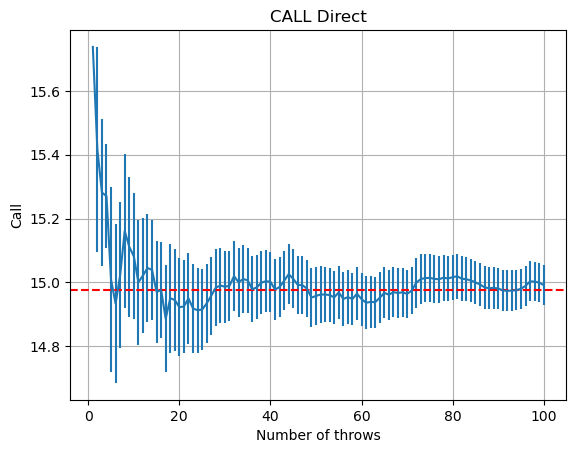

In [11]:
data1 = np.loadtxt("data1.txt")

x1 = data1[:,0]
mean1 = data1[:,1]
err1 = data1[:,2]


y= 14.975790778311286

plt.title("CALL Direct")
plt.errorbar(x1, mean1, yerr=err1,  label='Simulated')
plt.axhline(y=y, color='r', linestyle='--', label='Exact value')


plt.xlabel("Number of throws")
plt.ylabel("Call")
plt.grid(True)

plt.show()

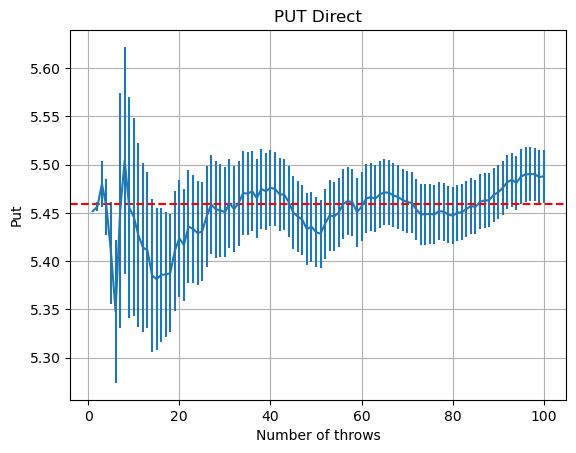

In [13]:
data2 = np.loadtxt("data2.txt")

x2 = data2[:,0]
mean2 = data2[:,1]
err2 = data2[:,2]



y= 5.4595325819072364
plt.title("PUT Direct")
plt.errorbar(x2, mean2, yerr=err2, label='Simulated')
plt.axhline(y=y, color='r', linestyle='--', label='Exact value')


plt.xlabel("Number of throws")
plt.ylabel("Put")
plt.grid(True)

plt.show()

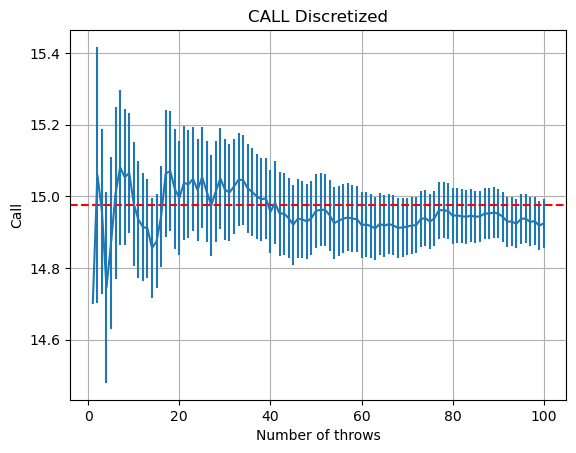

In [15]:
data3 = np.loadtxt("data3.txt")

x3 = data3[:,0]
mean3 = data3[:,1]
err3 = data3[:,2]



y= 14.975790778311286

plt.title("CALL Discretized")
plt.errorbar(x3, mean3, yerr=err3, label='Simulated')
plt.axhline(y=y, color='r', linestyle='--', label='Exact value')


plt.xlabel("Number of throws")
plt.ylabel("Call")
plt.grid(True)

plt.show()

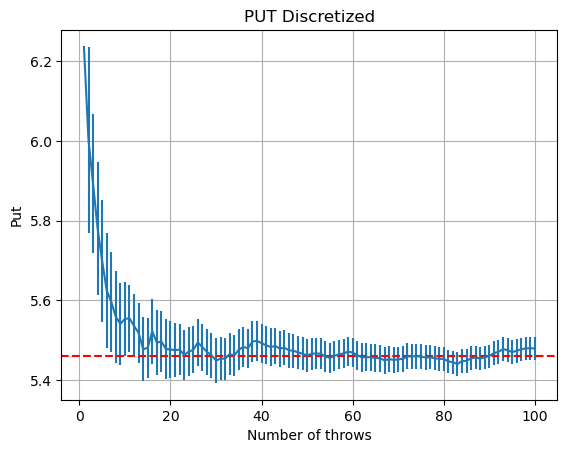

In [17]:
data4 = np.loadtxt("data4.txt")

x4 = data4[:,0]
mean4 = data4[:,1]
err4 = data4[:,2]



y= 5.4595325819072364
plt.title("PUT Discretized")
plt.errorbar(x4, mean4, yerr=err4, label='Simulated')
plt.axhline(y=y, color='r', linestyle='--', label='Exact value')


plt.xlabel("Number of throws")
plt.ylabel("Put")
plt.grid(True)

plt.show()

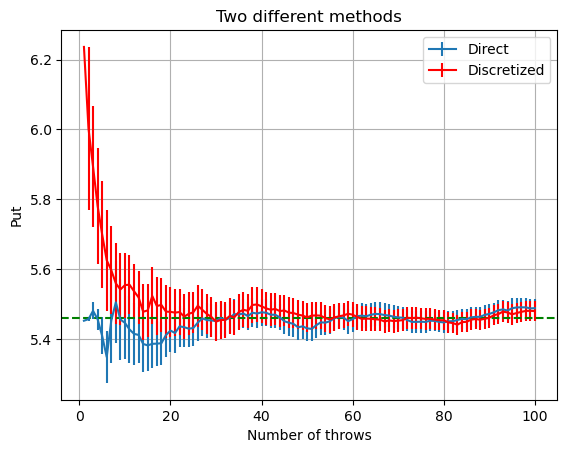

In [19]:
plt.title("Two different methods")
plt.errorbar(x2, mean2, yerr=err2, label='Direct')
plt.errorbar(x4, mean4, yerr=err4, color='red',label='Discretized')
plt.legend()
y= 5.4595325819072364
plt.axhline(y=y, color='g', linestyle='--', label='Exact value')

plt.xlabel("Number of throws")
plt.ylabel("Put")
plt.grid(True)

plt.show()

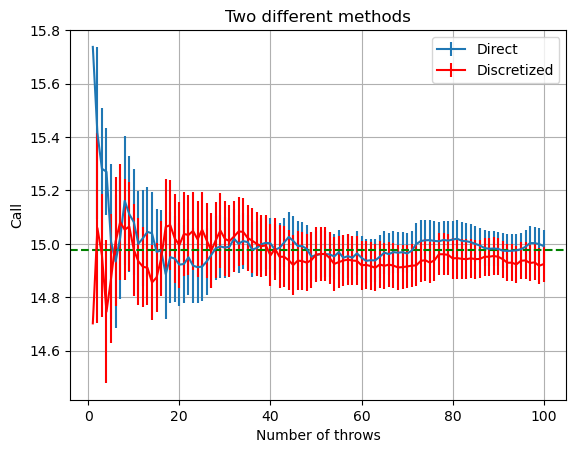

In [21]:
plt.title("Two different methods")
plt.errorbar(x1, mean1, yerr=err1, label='Direct')
plt.errorbar(x3, mean3, yerr=err3, color='red',label='Discretized')
plt.legend()

y= 14.975790778311286
plt.axhline(y=y, color='g', linestyle='--', label='Exact value')
plt.xlabel("Number of throws")
plt.ylabel("Call")
plt.grid(True)

plt.show()